In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk1-task3-earthquakes.ipynb")

# Task 3: `pandas` fundamentals with earthquake data

## Instructions
- First, update the following cell to have a link to *your* Homework 1 GitHub repository:

**UPDATE THIS LINK:**
https://github.com/katefrankland/eds220-hwk1.git


- This task covers topics on the lessons on [subsetting `pandas.DataFrames`](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-3-pandas-subsetting/lesson-3-pandas-subsetting.html) and [plotting](). The best strategy to solve it is to get together with your classmates and work on it together after these lecture.

- Review the [complete rubric for this task](https://docs.google.com/document/d/131OnUDOLpOl94SlaMU9nGqT998ABrjFS/edit?usp=sharing&ouid=111507336322611936333&rtpof=true&sd=true) before starting.

- **Make at least 5 commits at moments you think are adequate.** We'll check your repository and view the commit history.

- **Add comments for all your code.** Err on the side of commenting too much for now. Comments should follow best practices.


## Acknowledgement
This task was adapted from the *Pandas Fundamentals with Earthquake Data* assignment from the e-book [Earth and Environmental Data Science](https://earth-env-data-science.github.io/intro.html)

## About the data

For this task we are going to use simplified data from the [USGS Earthquakes Database](https://earthquake.usgs.gov/earthquakes/search/). This dataset is given in a single CSV file within the`data` folder (`data/earthquake_data.csv`) and has the following columns:

- time = date and time of event (all events from 2014)
- latitude = decimal degrees [-90,90]
- longitude = decimal degrees [-360,360]
- depth = depth of the event (km)
- mag =  magnitude of event
- id = event identifier
- place = where the event took place
- type = type of event

<!-- BEGIN QUESTION -->

## 1 

a. Import pandas (always with standard abbreviation!).

b. Use `pd.read_csv()` to import the `earthquake_data.csv` dataset and store it in the `raw_eqk` variable.


In [2]:
import pandas as pd 
import matplotlib as mp 
from matplotlib import colormaps 

raw_eqk = pd.read_csv('data/earthquake_data.csv') # Reading in the data

<!-- END QUESTION -->

Look at the head of the dataframe. Store the result in the `raw_eqk_head` variable. 

In [3]:
raw_eqk_head = raw_eqk.head() # Looking at the first few rows 

In [4]:
# View the dataframe
raw_eqk_head

,time,latitude,longitude,depth,mag,id,place,type
0,2014-01-31 23:53:37.000,60.252000,-152.7081,90.20,1.10,ak11155107,"26km S of Redoubt Volcano, Alaska",earthquake
1,2014-01-31 23:48:35.452,37.070300,-115.1309,0.00,1.33,nn00436847,"32km S of Alamo, Nevada",earthquake
2,2014-01-31 23:47:24.000,64.671700,-149.2528,7.10,1.30,ak11151142,"12km NNW of North Nenana, Alaska",earthquake
3,2014-01-31 23:30:54.000,63.188700,-148.9575,96.50,0.80,ak11151135,"22km S of Cantwell, Alaska",earthquake
4,2014-01-31 23:30:52.210,32.616833,-115.6925,10.59,1.34,ci37171541,"10km WNW of Progreso, Mexico",earthquake


In [5]:
grader.check("q1_c")

q1_c results: All test cases passed!

## 2
a. Print the shape of the `raw_eqk` dataframe. Store your answer in the `raw_eqk_shape` variable.

In [6]:
raw_eqk_shape = raw_eqk.shape #Find the number or rows and columns 

In [7]:
grader.check("q2_a")

q2_a results: All test cases passed!

b. Store the type of `raw_eqk`'s shape in the `raw_eqk_shape_type` variable.

In [8]:
raw_eqk_shape_type = type(raw_eqk_shape) #Finding the type of raw_eqk shape 

In [9]:
# View the dataframe
raw_eqk_shape_type

tuple

In [10]:
grader.check("q2_b")

q2_b results: All test cases passed!

c. Extract *only* the number of rows by accessing it from `raw_eqk`'s shape.Store your answer in the `num_rows` variable.  HINT: how do you index an element in a tuple?

In [11]:
num_rows = raw_eqk_shape[0]

In [12]:
grader.check("q2_c")

q2_c results: All test cases passed!

## 3

Get the unique values of the type of events. Store your answer in the `unique_events` variable.

In [13]:
unique_events = raw_eqk['type'].unique()
unique_events # printing the unique values of the type column 

array(['earthquake', 'quarry blast', 'quarry', 'mining explosion',
       'rock burst', 'explosion', 'landslide', 'sonicboom', 'sonic boom',
       'anthropogenic event', 'acoustic noise'], dtype=object)

In [14]:
grader.check("q3")

q3 results: All test cases passed!

# 4

a. Select only earthquake events and store them as `eqk` (variable name). Update the index of `eqk` to be the `id` column of the dataframe. 

In [17]:
eqk = raw_eqk[raw_eqk['type'] == "earthquake"].set_index('id') #subsetting using type and id 

In [18]:
# View the dataframe
eqk

,time,latitude,longitude,depth,mag,place,type
id,,,,,,,
ak11155107,2014-01-31 23:53:37.000,60.252000,-152.708100,90.20,1.10,"26km S of Redoubt Volcano, Alaska",earthquake
nn00436847,2014-01-31 23:48:35.452,37.070300,-115.130900,0.00,1.33,"32km S of Alamo, Nevada",earthquake
ak11151142,2014-01-31 23:47:24.000,64.671700,-149.252800,7.10,1.30,"12km NNW of North Nenana, Alaska",earthquake
ak11151135,2014-01-31 23:30:54.000,63.188700,-148.957500,96.50,0.80,"22km S of Cantwell, Alaska",earthquake
ci37171541,2014-01-31 23:30:52.210,32.616833,-115.692500,10.59,1.34,"10km WNW of Progreso, Mexico",earthquake
...,...,...,...,...,...,...,...
ak11453391,2014-12-01 00:10:16.000,60.963900,-146.762900,14.80,3.80,"29km SW of Valdez, Alaska",earthquake
ak11453395,2014-12-01 00:09:39.000,58.869100,-154.415900,108.40,2.40,"102km SSE of Old Iliamna, Alaska",earthquake
nc72358451,2014-12-01 00:09:25.350,38.843498,-122.825836,2.37,0.43,"9km WNW of Cobb, California",earthquake


In [19]:
grader.check("q4_a")

q4_a results: All test cases passed!

b. Check the new index by viewing the first 3 rows of `eqk`. Store your results in the `eqk_3` variable. 

In [20]:
eqk_3 = eqk.head(3) # want to view the first three rows 

In [21]:
# View the dataframe
eqk_3

,time,latitude,longitude,depth,mag,place,type
id,,,,,,,
ak11155107,2014-01-31 23:53:37.000,60.2520,-152.7081,90.2,1.10,"26km S of Redoubt Volcano, Alaska",earthquake
nn00436847,2014-01-31 23:48:35.452,37.0703,-115.1309,0.0,1.33,"32km S of Alamo, Nevada",earthquake
ak11151142,2014-01-31 23:47:24.000,64.6717,-149.2528,7.1,1.30,"12km NNW of North Nenana, Alaska",earthquake


In [22]:
grader.check("q4_b")

q4_b results: All test cases passed!

# 5

How many events were left out of `raw_eqk` when you selected ony earthqake events? Store your answer in the `omitted_events` variable. 

HINT: There are *many* ways you can get this information. One could be to use (2). 

In [24]:
omitted_events = len(raw_eqk) - len(eqk) # trying to see which rows are removed if only earthquake events are being used 

In [25]:
grader.check("q5")

q5 results: All test cases passed!

<!-- BEGIN QUESTION -->

# 6
Without creating any new variables, plot a histogram of the eartquake's magnitudes (`eqk` data). Add a title and change the color of your graph.

<Axes: title={'center': 'Earthquake Magnitudes'}, xlabel='Magnitude', ylabel='Frequency'>

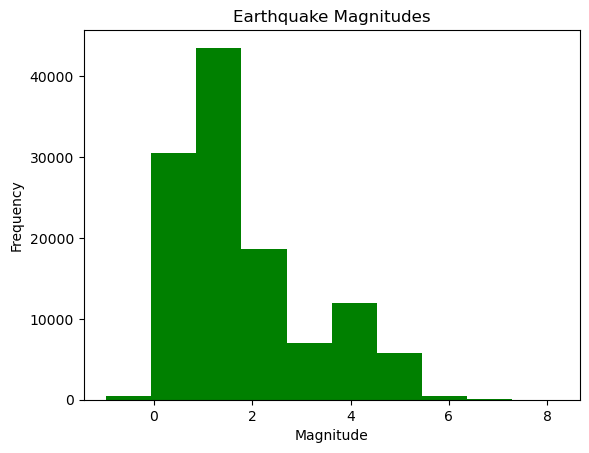

In [30]:
eqk['mag'].plot(kind = "hist",  # make histogram
                xlabel = "Magnitude", # add x axis 
                title = "Earthquake Magnitudes", # add title 
                color = "green" # add color 
               )

<!-- END QUESTION -->

# 7

a. Create a new variable `top20` with the 20 earthquakes with largest magnitude. HINT: check the method [`pandas.Series.nlargest`](https://pandas.pydata.org/docs/reference/api/pandas.Series.nlargest.html). Your answer should contain only the `id` and `mag` columns. 

In [31]:
top20 = eqk['mag'].nlargest(20) # using series.nlargest here to see largest earthquake magnitude 

In [32]:
# View the dataframe 
top20

id
usc000nzvd    8.2
usc000rki5    7.9
usc000p27i    7.7
usc000phx5    7.6
usb000pr89    7.5
usc000piqj    7.4
usb000slwn    7.3
usb000pq41    7.2
usc000pft9    7.1
usc000sxh8    7.1
usc000stdc    7.1
usb000sk6k    7.0
usc000mnvj    6.9
usc000nzwm    6.9
usb000r2hc    6.9
usc000rngj    6.9
usc000rkg5    6.9
usb000ruzk    6.9
usc000rr6a    6.9
usb000rzki    6.9
Name: mag, dtype: float64

In [33]:
grader.check("q7_a")

q7_a results: All test cases passed!

<!-- BEGIN QUESTION -->

b. Create a bar plot showing the magnitude of the top 20 earthquakes. Update the title, x-axis label, y-axis label, and color of the bars. 

<Axes: title={'center': 'Top 20 Largest Earthquakes'}, xlabel='ID', ylabel='Magnitude'>

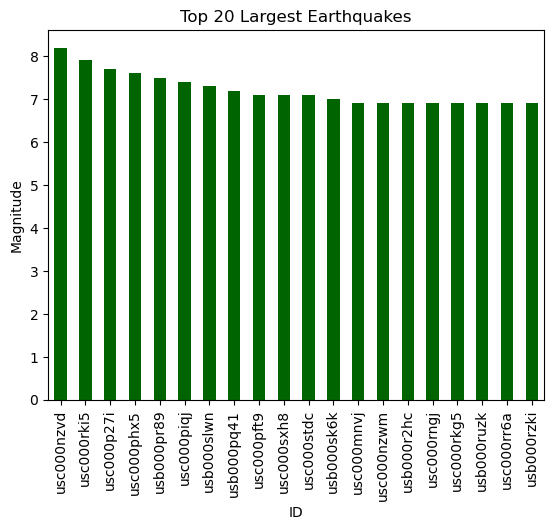

In [36]:
top20.plot(kind = "bar", # create barplot 
           xlabel = "ID", # add x label
           ylabel = "Magnitude", # add y label 
           color = "darkgreen", # add color 
           title = "Top 20 Largest Earthquakes" # add title 
          )

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. What is the role of the `top20` index in the graph? What would have happened if we had not updated the index?

The purpose of the top20 index is to make sure that index values are corresponding to the earthquake ID number, and not the index. 

<!-- END QUESTION -->

# 8 
We are interested in the place, magnitude, and depth of the top 20 earthquakes with largest magnitude. Select this data from the `eqk` data frame. Store your answer in the `top20_filtered` variable. 

HINT: This is a "select rows and columns simultaneously" from `eqk` exercise. To select the rows you could use the index of `top20`. Make sure your columns are in the following order to pass the test: `place`, `mag`, `depth`. 

In [37]:
top20_filtered = eqk.loc[top20.index, ['place', 'mag', 'depth']] # using loc to select columns based on name, and using .index to match with the top20 dataframe 

In [38]:
# View the dataframe
top20_filtered

,place,mag,depth
id,,,
usc000nzvd,"94km NW of Iquique, Chile",8.2,25.00
usc000rki5,"19km SE of Little Sitkin Island, Alaska",7.9,109.00
usc000p27i,"53km SW of Iquique, Chile",7.7,22.40
usc000phx5,"93km SSE of Kirakira, Solomon Islands",7.6,22.56
usb000pr89,"70km SW of Panguna, Papua New Guinea",7.5,43.37
usc000piqj,"112km S of Kirakira, Solomon Islands",7.4,39.00
usb000slwn,"74km S of Intipuca, El Salvador",7.3,40.00
usb000pq41,"33km ESE of Petatlan, Mexico",7.2,24.00
usc000pft9,"56km WSW of Panguna, Papua New Guinea",7.1,60.53


In [39]:
grader.check("q8")

q8 results: All test cases passed!

<!-- BEGIN QUESTION -->

# 9 

Without creating any new variables, visualize the locations of eartquakes with magnitude greter than 5 by creating a scatter plot of their latitude and longitude. Make the following adjustments to the basic plot:
- update the title
- color the points by magnitude (HINT: [check the `c` parameter here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.plot.scatter.html))
- adjust the `alpha` (transparency) argument
- adjust the `colormap` argument to maket it look prettier. [Click for ideas of sequential colormaps.](https://matplotlib.org/stable/users/explain/colors/colormaps.html)


AttributeError: PathCollection.set() got an unexpected keyword argument 'colormaps'

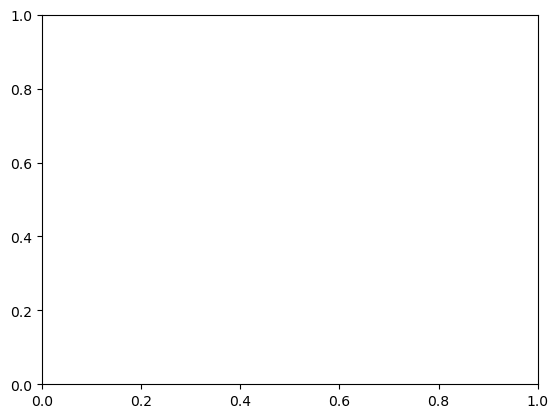

In [41]:
eqk[eqk["mag"]>5].plot(
    kind='scatter', # creating scatter plot 
    x='latitude', # setting x axis 
    y='longitude', # setting y axis 
    c='mag', # using magnitude to color points 
    xlabel = 'latitude', # labeling x 
    ylabel = 'longitude', # labeling y 
    alpha = 0.8, # transparency for points 
colormaps = 'BuGn'
                      )
                       
                       

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [ ]:
grader.check_all()

<!-- END QUESTION -->

